# 01 — Load and clean the data

**Project question.** How much of a smartphone's Indian launch price can its listed hardware specs explain, and how much extra (or less) does each brand charge for the same specs? We call that extra the **brand premium**.

This notebook turns the raw CSV into a clean table with one row per phone and only numeric or categorical columns that a model can use. All the text parsing lives in `src/features.py` in the function `build_features(df)`, so the same rules can be reused later and checked in one place. This notebook only *drops* rows. Every drop is counted, so we can say exactly what we removed and why.

## Problem statement
**Question.** How accurately can a smartphone's Indian launch price be predicted from its listed specifications, chip and brand, and how much of the price is explained by **brand** rather than **hardware**?

**Target and unit.** The launch price in India, in rupees (₹). We model the **natural log of the price**, because spec effects act as percentages ("+256 GB adds about x %", not "adds ₹y") and prices are right-skewed (a few very expensive phones). The full justification, with numbers, is in Step 9 below.

**Unit of analysis.** One row = one **phone variant**: a specific RAM/storage configuration of a model (e.g. "iPhone 16 128GB" and "iPhone 16 256GB" are two rows).

**When is a prediction made?** At the moment a phone's specs, chip, brand and launch year are known but its Indian price is not: for example at announcement, or when a buyer judges a phone from its listed specs. Every input we use is available at that moment. Nothing derived from the price itself, and none of the other countries' prices in the file, is used as an input.

**Limits of the claim**
- Predictions describe **typical launch pricing in this dataset**, not a phone's "true worth" and not today's street price.
- Coefficients (e.g. a brand premium) are **associations, not causes**: they compare phones that differ in one feature, with the others equal.
- Results apply only to the brands, launch years (2014–2025) and price range covered by the data.
- Brands with few phones have uncertain estimates.
- Quality factors that are not in the data (camera quality, display type, materials, years of software updates) are outside the model.

### Step 0 — Imports and loading the raw file
We use **pandas**, a library for tables (called *DataFrames*), and **NumPy** for maths. The file is read with `encoding="latin-1"` because it has a few non-UTF-8 characters. We add `../src` to Python's search path so we can import our own `features.py`.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
from features import build_features, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

raw = pd.read_csv("../data/raw/Mobiles Dataset (2025).csv", encoding="latin-1")
print("Raw shape (rows, columns):", raw.shape)
raw.head()

Raw shape (rows, columns): (930, 15)


,Company Name,Model Name,Mobile Weight,RAM,Front Camera,Back Camera,Processor,Battery Capacity,Screen Size,Launched Price (Pakistan),Launched Price (India),Launched Price (China),Launched Price (USA),Launched Price (Dubai),Launched Year
0,Apple,iPhone 16 128GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 224,999","INR 79,999","CNY 5,799",USD 799,"AED 2,799",2024
1,Apple,iPhone 16 256GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 234,999","INR 84,999","CNY 6,099",USD 849,"AED 2,999",2024
2,Apple,iPhone 16 512GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 244,999","INR 89,999","CNY 6,499",USD 899,"AED 3,199",2024
3,Apple,iPhone 16 Plus 128GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"PKR 249,999","INR 89,999","CNY 6,199",USD 899,"AED 3,199",2024
4,Apple,iPhone 16 Plus 256GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"PKR 259,999","INR 94,999","CNY 6,499",USD 949,"AED 3,399",2024


## Data source, access and variables
**Provenance** (from the Kaggle page, accessed 23 October 2026):
- **Title:** Mobiles Dataset (2025)
- **Author:** Abdul Malik (Kaggle user `abdulmalik1518`)
- **URL:** https://www.kaggle.com/datasets/abdulmalik1518/mobiles-dataset-2025
- **DOI:** https://doi.org/10.34740/kaggle/dsv/10780255
- **Licence:** Apache 2.0
- **Last updated:** 18 February 2025 (Version 1)
- **File:** `Mobiles Dataset (2025).csv`, 140.32 kB, 15 columns. Our copy in `data/raw/` has the same size (140,323 bytes).
- **Stated coverage:** temporal coverage 01/05/2025 to 02/15/2025, geospatial coverage "Worldwide".
- **Stated collection method:** the author collected the data "by my personal searching from different websites"; no list of websites is given. The data card says the prices are "the official launch prices … at the time of [first] release".

**What is unknown or limited**
- **Who recorded the prices and from where** is not documented beyond "different websites"; there is no source per row.
- **Whether the prices are official launch prices** cannot be checked from the file; it has no date or source column for prices.
- **Whether an "India" price exists for phones never officially sold in India**: every row has an India price, including phones that were sold only in China. Section C below checks this.
- **No documentation of the collection method** (dates of collection, rules for variants, currency handling).
- **Prices for five countries in one file** (Pakistan, India, China, USA, Dubai). Only the India price is our target; the others are never used as inputs.
- **No personal data** is involved: the rows describe phone models, not people.

**Data dictionary.** For each of the 15 raw columns: what it means, its unit, an example raw value, what we parse it into (and the parsed type), how many values are missing (in the raw file, and after parsing), and how we use it. `build_features` (from `src/features.py`) does the parsing; here we only run it to describe the result. The China price is parsed with the same `parse_price` rule, for the check in section C.

In [2]:
from features import parse_price

DICTIONARY = [  # raw column, meaning, unit, parsed column, how we use it
    ("Company Name", "brand / manufacturer", "-", "brand", "feature (brand; small brands -> 'Other')"),
    ("Model Name", "model name, usually with storage", "-", "storage_gb", "storage feature + model_group (for the split)"),
    ("Mobile Weight", "weight", "g", "weight_g", "feature"),
    ("RAM", "memory", "GB", "ram_gb", "feature (as log2_ram)"),
    ("Front Camera", "selfie camera resolution", "MP", "front_mp", "feature"),
    ("Back Camera", "rear camera resolutions", "MP", "main_back_mp", "feature (largest MP, and count of cameras)"),
    ("Processor", "chipset", "-", "chip_group", "feature (11 families -> chip_group)"),
    ("Battery Capacity", "battery size", "mAh", "battery_mah", "feature"),
    ("Screen Size", "display diagonal (main screen)", "inches", "screen_in", "feature"),
    ("Launched Price (Pakistan)", "launch price in Pakistan", "PKR", None, "not used as input (would leak price information)"),
    ("Launched Price (India)", "launch price in India", "INR (₹)", "price_inr", "TARGET (as log_price)"),
    ("Launched Price (China)", "launch price in China", "CNY", "price_cny", "data-quality check only (section C); not used as input (would leak price information)"),
    ("Launched Price (USA)", "launch price in the USA", "USD", None, "not used as input (would leak price information)"),
    ("Launched Price (Dubai)", "launch price in Dubai", "AED", None, "not used as input (would leak price information)"),
    ("Launched Year", "launch year", "year", "year", "feature"),
]

In [3]:
parsed = build_features(raw)
parsed["price_cny"] = raw["Launched Price (China)"].apply(parse_price)
rows = []
for col, meaning, unit, parsed_col, use in DICTIONARY:
    raw_missing = raw[col].isna() | raw[col].astype(str).str.strip().isin(["", "Not available"])
    rows.append({"raw column": col, "meaning": meaning, "unit": unit, "example raw value": raw[col].iloc[0],
                 "parsed into": parsed_col or "-",
                 "parsed type": str(parsed[parsed_col].dtype) if parsed_col else "-",
                 "missing (raw)": int(raw_missing.sum()),
                 "missing (parsed)": int(parsed[parsed_col].isna().sum()) if parsed_col else "-",
                 "how we use it": use})
with pd.option_context("display.max_colwidth", 60):
    display(pd.DataFrame(rows).set_index("raw column"))

,meaning,unit,example raw value,parsed into,parsed type,missing (raw),missing (parsed),how we use it
raw column,,,,,,,,
Company Name,brand / manufacturer,-,Apple,brand,str,0,0,feature (brand; small brands -> 'Other')
Model Name,"model name, usually with storage",-,iPhone 16 128GB,storage_gb,float64,0,152,storage feature + model_group (for the split)
Mobile Weight,weight,g,174g,weight_g,float64,0,0,feature
RAM,memory,GB,6GB,ram_gb,float64,0,0,feature (as log2_ram)
Front Camera,selfie camera resolution,MP,12MP,front_mp,float64,0,0,feature
Back Camera,rear camera resolutions,MP,48MP,main_back_mp,float64,0,0,"feature (largest MP, and count of cameras)"
Processor,chipset,-,A17 Bionic,chip_group,str,0,0,feature (11 families -> chip_group)
Battery Capacity,battery size,mAh,"3,600mAh",battery_mah,float64,0,0,feature
Screen Size,display diagonal (main screen),inches,6.1 inches,screen_in,float64,0,0,feature


**Takeaway:** the file has 15 columns and 930 rows, with almost no empty cells. The only raw gap is one Pakistan price written as "Not available". The China price is present for all 930 phones (one is written "¥13,999" instead of "CNY …", which parses the same). The real gap appears only after parsing: **152 phones have no storage size in their model name**, which is why Step 7 drops most of them. Of the five price columns, only the India price is used (as the target). The China price is used only for the data-quality check below. The Pakistan, USA and Dubai prices are never used, because another country's price for the same phone would give the model the answer (leakage).

### Step 1 — Parse the text columns into numbers
Every spec column is stored as text, such as `"8GB"`, `"5,000mAh"`, `"50MP + 8MP"` or `"INR 79,999"`. `build_features` converts them:

| new column | from | rule |
|---|---|---|
| `price_inr` | Launched Price (India) | keep only the digits. This also handles Indian commas like "1,49,999". |
| `ram_gb` | RAM | number before "GB". "8GB / 12GB" lists two variants, so we keep the base one (8). |
| `weight_g`, `battery_mah`, `screen_in` | Weight, Battery, Screen | first number (commas removed). Foldables list two screens, and we keep the first one, which is the main screen. |
| `front_mp`, `main_back_mp` | cameras | the **largest** "xxMP" number. We treat it as the main camera. Text like "4K" is ignored because it is not followed by "MP". |
| `n_back_cameras` | Back Camera | how many "xxMP" numbers there are |
| `storage_gb` | Model Name | "128GB" gives 128 and "1TB" gives 1024. If no storage is written in the name, the value is missing. |

It also builds `brand`, `chip_family`, `model_group` and `is_tablet` (explained below). `build_features` does not drop any rows.

To check the parsing by eye, we print 15 random phones with each raw string next to its parsed number.

In [4]:
df = build_features(raw)

check_pairs = [
    ("Launched Price (India)", "price_inr"), ("RAM", "ram_gb"), ("Model Name", "storage_gb"),
    ("Mobile Weight", "weight_g"), ("Battery Capacity", "battery_mah"), ("Screen Size", "screen_in"),
    ("Front Camera", "front_mp"), ("Back Camera", "main_back_mp"), ("Back Camera", "n_back_cameras"),
]
sample = df.sample(15, random_state=42)
for raw_col, new_col in check_pairs:
    print(f"\n=== {raw_col}  ->  {new_col}")
    print(sample[[raw_col, new_col]].to_string(index=False))


=== Launched Price (India)  ->  price_inr
Launched Price (India)  price_inr
            INR 24,999    24999.0
             INR 9,999     9999.0
           INR 109,999   109999.0
            INR 42,999    42999.0
            INR 54,999    54999.0
            INR 54,999    54999.0
            INR 69,900    69900.0
            INR 19,499    19499.0
            INR 34,999    34999.0
            INR 14,999    14999.0
            INR 18,999    18999.0
            INR 44,999    44999.0
            INR 16,999    16999.0
            INR 39,999    39999.0
            INR 14,999    14999.0

=== RAM  ->  ram_gb
 RAM  ram_gb
12GB    12.0
 3GB     3.0
 6GB     6.0
12GB    12.0
12GB    12.0
12GB    12.0
 8GB     8.0
 8GB     8.0
16GB    16.0
 6GB     6.0
 4GB     4.0
 8GB     8.0
 4GB     4.0
12GB    12.0
 6GB     6.0

=== Model Name  ->  storage_gb
         Model Name  storage_gb
        Hot 50 Pro+         NaN
           C32 64GB        64.0
iPhone 14 Pro 128GB       128.0
 Reno8 Pro 5G 256GB     

The tricky strings deserve a separate look: foldable screens, cameras with labels such as "(Main)", "12MP / 4K" fronts, and RAM ranges.

In [5]:
tricky = (
    df["Screen Size"].str.contains(r"\(")
    | df["Back Camera"].str.contains(r"\(")
    | df["Front Camera"].str.contains(r"/|Dual|,")
    | df["RAM"].str.contains("/")
)
print("Number of tricky strings:", tricky.sum())
df.loc[tricky, ["Model Name", "Screen Size", "screen_in", "Back Camera", "main_back_mp",
                "n_back_cameras", "Front Camera", "front_mp", "RAM", "ram_gb"]].drop_duplicates("Model Name").head(15)

Number of tricky strings: 87


,Model Name,Screen Size,screen_in,Back Camera,main_back_mp,n_back_cameras,Front Camera,front_mp,RAM,ram_gb
6,iPhone 16 Pro 128GB,6.1 inches,6.1,50MP + 12MP,50.0,2,12MP / 4K,12.0,6GB,6.0
7,iPhone 16 Pro 256GB,6.1 inches,6.1,50MP + 12MP,50.0,2,12MP / 4K,12.0,8GB,8.0
8,iPhone 16 Pro 512GB,6.1 inches,6.1,50MP + 12MP,50.0,2,12MP / 4K,12.0,8GB,8.0
9,iPhone 16 Pro Max 128GB,6.7 inches,6.7,48MP + 12MP,48.0,2,12MP / 4K,12.0,6GB,6.0
10,iPhone 16 Pro Max 256GB,6.7 inches,6.7,48MP + 12MP,48.0,2,12MP / 4K,12.0,8GB,8.0
11,iPhone 16 Pro Max 512GB,6.7 inches,6.7,48MP + 12MP,48.0,2,12MP / 4K,12.0,8GB,8.0
18,iPhone 15 Pro 128GB,6.1 inches,6.1,48MP + 12MP,48.0,2,12MP / 4K,12.0,6GB,6.0
19,iPhone 15 Pro 256GB,6.1 inches,6.1,48MP + 12MP,48.0,2,12MP / 4K,12.0,8GB,8.0
20,iPhone 15 Pro 512GB,6.1 inches,6.1,48MP + 12MP,48.0,2,12MP / 4K,12.0,8GB,8.0
21,iPhone 15 Pro Max 128GB,6.7 inches,6.7,48MP + 12MP,48.0,2,12MP / 4K,12.0,6GB,6.0


## Quality check: are the India prices real Indian launch prices?
The file gives an India price for **every** phone, even for phones that, as far as we know, were sold only in China. If someone filled such gaps by **converting** the China price into rupees, those "India prices" would not be real Indian launch prices.

**The test.** For every phone with both an India price (₹) and a China price (CNY) we compute

**ratio = India price (₹) / China price (CNY)**

If the India prices were simple currency conversions, this ratio would be **almost the same for every phone** and equal to the exchange rate. Real local prices are set separately in each market, so the ratio varies by brand (e.g. import duties, local competition, how a brand positions itself in each country). At this point the data still contains every raw row (tablets and duplicates are removed later), so the check covers the whole file.

In [6]:
import matplotlib.pyplot as plt

df["price_cny"] = raw["Launched Price (China)"].apply(parse_price)
df["india_china_ratio"] = df["price_inr"] / df["price_cny"]
has_both = df["india_china_ratio"].notna()
print(f"phones with both prices: {has_both.sum()} of {len(df)}")
print(f"overall median ratio: {df['india_china_ratio'].median():.2f} ₹ per CNY")
print(f"middle 50 % of phones: {df['india_china_ratio'].quantile(0.25):.2f} to {df['india_china_ratio'].quantile(0.75):.2f}")
print("\nRatio by brand:")
print(df.groupby("brand")["india_china_ratio"].describe()[["count", "25%", "50%", "75%"]].round(2)
        .sort_values("50%").to_string())

phones with both prices: 930 of 930
overall median ratio: 12.50 ₹ per CNY
middle 50 % of phones: 11.12 to 14.00

Ratio by brand:
          count    25%    50%    75%
brand                               
Lenovo     15.0   9.00   9.42  13.72
POCO       32.0  10.01  10.60  11.67
Vivo       86.0  10.01  10.82  12.77
Infinix    56.0  10.51  10.92  11.35
Google     21.0  10.49  11.11  12.50
Nokia      11.0  10.85  11.12  12.59
OnePlus    53.0  10.86  11.67  12.18
Tecno      39.0  11.75  12.00  12.51
Samsung    88.0  11.26  12.14  13.22
Oppo      129.0  11.37  12.22  13.34
Motorola   62.0  11.73  12.28  13.29
iQOO        3.0  12.70  12.82  13.45
Realme     69.0  12.50  13.08  13.79
Apple      97.0  13.44  14.52  15.39
Honor      91.0  12.33  14.55  15.89
Huawei     42.0  13.35  14.84  15.72
Sony        9.0  15.00  15.15  15.30
Xiaomi     27.0  11.96  16.93  18.75


**Box plot** of the ratio by brand (sorted by the median). The box covers the middle 50 % of a brand's phones, the line inside is the median, and the dots are phones outside the whiskers (1.5 × the box height).

/tmp/ipykernel_20439/1407748548.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([df.loc[(df["brand"] == b) & has_both, "india_china_ratio"] for b in order], vert=False)


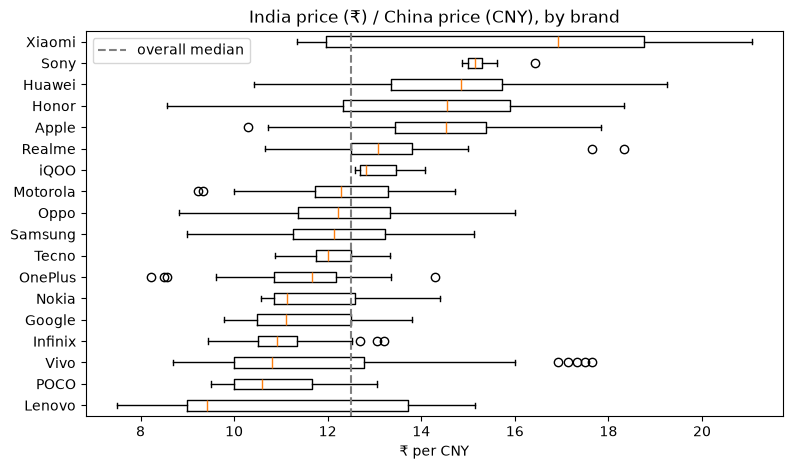

In [7]:
order = df.groupby("brand")["india_china_ratio"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([df.loc[(df["brand"] == b) & has_both, "india_china_ratio"] for b in order], vert=False)
ax.set_yticks(range(1, len(order) + 1), order)
ax.axvline(df["india_china_ratio"].median(), color="gray", linestyle="--", label="overall median")
ax.set(title="India price (₹) / China price (CNY), by brand", xlabel="₹ per CNY")
ax.legend()
plt.show()

**Takeaway — India prices are not one simple currency conversion.** All 930 phones have both prices. The overall median ratio is **12.50 ₹ per CNY**, but the middle half of the phones ranges from 11.12 to 14.00, and the brands differ clearly:
- **Relatively cheaper in India than in China:** Lenovo (median 9.4), POCO (10.6), Vivo (10.8), Infinix (10.9).
- **Relatively more expensive in India:** Apple (14.5), Honor (14.6), Huawei (14.8), Sony (15.2) and Xiaomi (16.9, also the widest spread, 12.0 to 18.8 for its middle half).

This is the pattern expected from prices set separately in each market, not from one exchange rate. The test cannot prove that a single phone's India price is real, though. For example, the Huawei phones (sold only in China, see below) have ordinary-looking ratios (median 14.8), so the ratio alone would not have caught them. That is why rule (a) below uses outside information.

**Flag doubtful India prices.** We add a column `india_price_flag` with a short reason (empty = no doubt):
- **(a) Not officially sold in India.** Huawei phones launched after 2019. Business Today wrote in February 2025 that "Huawei hasn't sold phones in India in quite some time" ([source](https://www.businesstoday.in/technology/news/story/huawei-mate-xt-tri-fold-phone-launched-globally-will-it-launch-in-india-465132-2025-02-19), 19 Feb 2025). Honor phones are not flagged here because none of them is left after cleaning (Step 7), and we do not flag other brands without a source.
- **(b) Unusual ratio for the brand.** The phone's ratio lies outside its brand's **1.5 × IQR range**: below Q1 − 1.5·IQR or above Q3 + 1.5·IQR, where Q1 and Q3 are the brand's 25th and 75th percentiles and IQR = Q3 − Q1 (the same rule as the whiskers in the box plot).

We **do not drop** flagged phones; the flag is only kept as a column, so later notebooks can check whether removing them changes the results.

In [8]:
q1 = df.groupby("brand")["india_china_ratio"].transform(lambda s: s.quantile(0.25))
q3 = df.groupby("brand")["india_china_ratio"].transform(lambda s: s.quantile(0.75))
outlier = (df["india_china_ratio"] < q1 - 1.5 * (q3 - q1)) | (df["india_china_ratio"] > q3 + 1.5 * (q3 - q1))
huawei_late = (df["Company Name"].str.strip() == "Huawei") & (df["year"] >= 2020)

df["india_price_flag"] = ""
df.loc[huawei_late, "india_price_flag"] = "Huawei after 2019: not officially sold in India"
df.loc[outlier & ~huawei_late, "india_price_flag"] = "India/China price ratio is an outlier for its brand"
df.loc[outlier & huawei_late, "india_price_flag"] += "; ratio is an outlier for its brand"

flagged = df[df["india_price_flag"] != ""]
print(f"flagged rows in the raw file: {len(flagged)} of {len(df)}\n")
print(flagged.groupby(["brand", "india_price_flag"]).size().rename("rows").to_string())

flagged rows in the raw file: 60 of 930

brand     india_price_flag                                   
Apple     India/China price ratio is an outlier for its brand     1
Huawei    Huawei after 2019: not officially sold in India        42
Infinix   India/China price ratio is an outlier for its brand     3
Motorola  India/China price ratio is an outlier for its brand     2
OnePlus   India/China price ratio is an outlier for its brand     4
Realme    India/China price ratio is an outlier for its brand     2
Sony      India/China price ratio is an outlier for its brand     1
Vivo      India/China price ratio is an outlier for its brand     5


The flagged phones with their prices and ratios (sorted by brand, then ratio).

In [9]:
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 50):
    display(flagged.sort_values(["brand", "india_china_ratio"])[
        ["brand", "Model Name", "year", "Launched Price (India)", "Launched Price (China)",
         "india_china_ratio", "india_price_flag"]].round(2))

,brand,Model Name,year,Launched Price (India),Launched Price (China),india_china_ratio,india_price_flag
77,Apple,iPhone XR 64GB,2018,"INR 64,900","CNY 6,299",10.30,India/China price ratio is an outlier for its ...
686,Huawei,MatePad Pro 12.2 512GB,2024,"INR 49,990","CNY 4,799",10.42,Huawei after 2019: not officially sold in India
687,Huawei,MatePad Pro 13.2 512GB,2024,"INR 58,590","CNY 5,199",11.27,Huawei after 2019: not officially sold in India
640,Huawei,P60,2023,"INR 84,999","CNY 6,988",12.16,Huawei after 2019: not officially sold in India
650,Huawei,Pura 70,2024,"INR 84,999","CNY 6,988",12.16,Huawei after 2019: not officially sold in India
641,Huawei,P60 Pro,2023,"INR 99,999","CNY 7,988",12.52,Huawei after 2019: not officially sold in India
651,Huawei,Pura 70 Pro,2024,"INR 99,999","CNY 7,988",12.52,Huawei after 2019: not officially sold in India
652,Huawei,Pura 70 Pro+,2024,"INR 114,999","CNY 8,988",12.79,Huawei after 2019: not officially sold in India
632,Huawei,Nova 9 Pro,2021,"INR 44,999","CNY 3,499",12.86,Huawei after 2019: not officially sold in India
653,Huawei,Pura 70 Ultra,2024,"INR 129,999","CNY 9,988",13.02,Huawei after 2019: not officially sold in India


**Takeaway — 60 of the 930 raw rows are flagged:**
- **42 rows by rule (a):** all 42 Huawei rows in the file, phones and tablets, launched in 2021–2024.
- **18 rows by rule (b), an outlier ratio for their brand:**
  - **Vivo (5):** the X200 series, ratio 16.9–17.7 vs a Vivo median of 10.8.
  - **OnePlus (4):** e.g. Nord CE 3 at 8.2, relatively cheap in India.
  - **Infinix (3)**, **Motorola (2)** (Moto E40 Plus, 9.2–9.3) and **Realme (2)** (GT 7 Pro, 17.7–18.3).
  - **Apple (1)** (iPhone XR, 10.3) and **Sony (1)**.

One flagged phone confirms that the check works. The **Infinix Zero Flip** is flagged by its dataset India price (₹32,999, ratio 13.2), and our web lookup in Step 7b had already found that this price was wrong (the verified India launch price is ₹54,999). In the clean data its price is the verified one, so its flag describes the replaced dataset price. The ratio column always uses the original dataset price. No phone is dropped because of a flag.

### Step 2 — Storage from the model name, and `model_group`
Storage is not its own column. It is written inside the model name ("iPhone 16 **128GB**"). Many phones are sold in several storage variants that are otherwise identical.

`model_group` is the model name with the storage removed (plus the brand), so "iPhone 16 128GB" and "iPhone 16 256GB" both become `apple | iphone 16`. We use it **only** to split the data later, so that all variants of one phone go to the same side. It is never a model input, because it is just a name.

In [10]:
print(df["storage_gb"].value_counts(dropna=False).sort_index())
print("\nExample groups:")
print(df.loc[df["brand"] == "Apple", ["Model Name", "storage_gb", "model_group"]].head(6).to_string(index=False))

storage_gb
16.0        5
32.0       13
64.0       82
128.0     314
256.0     275
512.0      84
1024.0      4
2048.0      1
NaN       152
Name: count, dtype: int64

Example groups:
          Model Name  storage_gb            model_group
     iPhone 16 128GB       128.0      apple | iphone 16
     iPhone 16 256GB       256.0      apple | iphone 16
     iPhone 16 512GB       512.0      apple | iphone 16
iPhone 16 Plus 128GB       128.0 apple | iphone 16 plus
iPhone 16 Plus 256GB       256.0 apple | iphone 16 plus
iPhone 16 Plus 512GB       512.0 apple | iphone 16 plus


### Step 3 — Keep track of every row we drop
We record the row count after each cleaning step in a small log, so the final table shows exactly where rows were lost.

In [11]:
drop_log = [("raw file", len(df))]

def log_step(name, data):
    drop_log.append((name, len(data)))
    print(f"{name}: {len(data)} rows left ({drop_log[-2][1] - len(data)} dropped)")

### Step 4 — Remove tablets
The question is about **phones**. Tablets have much bigger screens and batteries and a different price logic, so they would distort the spec–price relationship. Any model name that contains "pad" or "tab" (case-insensitive) is a tablet. This catches iPad, Galaxy Tab, MatePad, Xpad, Megapad, MagicPad and Honor "Tablet V7". We print the matches to confirm that no real phone is caught by mistake.

In [12]:
tablets = df[df["is_tablet"]]
print("Tablets found:", len(tablets))
print(tablets.groupby("brand")["Model Name"].apply(lambda s: ", ".join(s.head(4)) + (" ..." if len(s) > 4 else "")).to_string())

df = df[~df["is_tablet"]].copy()
log_step("remove tablets", df)

Tablets found: 100
brand
Apple      iPad Air 10.9-inch 64GB, iPad Air 10.9-inch 25...
Honor                    Pad 6, Pad X6, Pad 7, Tablet V7 ...
Huawei        MatePad Pro 12.2 512GB, MatePad Pro 13.2 512GB
Infinix                   Xpad, Xpad 5G, Xpad Lite, Xpad Pro
OnePlus          OnePlus Pad, OnePlus Pad 2, OnePlus Pad Pro
Oppo       Pad 3 128GB, Pad 3 256GB, Pad 3 Pro 256GB, Pad...
POCO                              Pad 5G 128GB, Pad 5G 256GB
Realme     Pad 64GB, Pad 128GB, Pad 2 128GB, Pad 2 256GB ...
Samsung    Galaxy Tab S9 Ultra 256GB, Galaxy Tab S9+ 256G...
Tecno                        Megapad 11 256GB, Megapad 128GB
Vivo       Pad 128GB, Pad 2 256GB, Pad Air 128GB, Pad 3 1...
iQOO                 Pad 128GB, Pad 2 256GB, Pad 2 Pro 256GB
remove tablets: 830 rows left (100 dropped)


### Step 5a — Merge brand spellings
The raw data has both "Poco" and "POCO". `build_features` already maps "Poco" to "POCO". Here we check that no other brand appears twice under different spellings. Grouping small brands into "Other" happens at the end (Step 8), after all row drops, because the rule depends on the final counts.

In [13]:
print("Raw Company Name values:", sorted(raw["Company Name"].unique()))
print("Cleaned brand values:   ", sorted(df["brand"].unique()))

Raw Company Name values: ['Apple', 'Google', 'Honor', 'Huawei', 'Infinix', 'Lenovo', 'Motorola', 'Nokia', 'OnePlus', 'Oppo', 'POCO', 'Poco', 'Realme', 'Samsung', 'Sony', 'Tecno', 'Vivo', 'Xiaomi', 'iQOO']
Cleaned brand values:    ['Apple', 'Google', 'Honor', 'Huawei', 'Infinix', 'Lenovo', 'Motorola', 'Nokia', 'OnePlus', 'Oppo', 'POCO', 'Realme', 'Samsung', 'Sony', 'Tecno', 'Vivo', 'Xiaomi']


### Step 6 — Chip family from the processor
There are about 230 different processor strings, which is far too many categories for 700 phones. We group them into 11 **families** that roughly reflect performance tier:

- `apple_a`: Apple A-series (A11 … A18)
- `snapdragon_8`: Qualcomm flagships. This means "8 Gen 1/2/3", "8+ Gen", "8s Gen", "8 Elite", **and** the older three-digit flagships 835–888, which were the top chip of their year.
- `snapdragon_other`: every other Snapdragon (4xx, 6xx, 7xx, "6 Gen", "7s Gen", …)
- `dimensity_high`: MediaTek Dimensity 8000/9000 series
- `dimensity_other`: Dimensity 6000/7000/700–1300
- `helio`: MediaTek Helio (budget). Strings like "MediaTek G99" are Helio chips too.
- `exynos`, `tensor`, `kirin`, `unisoc`: Samsung, Google, Huawei and Unisoc chips
- `other`: anything left over

The table below lists every raw processor string next to the family it was given, so the mapping can be checked line by line.

**For the models we use one more column, `chip_group`.** It is identical to `chip_family` except that `apple_a` and `snapdragon_8` are merged into `flagship_sd8_or_apple`. Only Apple uses Apple chips, so an `apple_a` column would be an exact copy of the `Apple` brand column, and a linear model could not separate the two (Phase 4 shows this). `chip_family` is kept for description and plots.

In [14]:
chip_table = (df.groupby(["chip_family", "Processor"]).size()
                .rename("phones").reset_index()
                .sort_values(["chip_family", "phones"], ascending=[True, False]))
with pd.option_context("display.max_rows", 300):
    print(chip_table.to_string(index=False))
print("\nPhones per family:\n", df["chip_family"].value_counts().to_string())

     chip_family                        Processor  phones
         apple_a                       A15 Bionic      18
         apple_a                       A16 Bionic      18
         apple_a                       A14 Bionic      12
         apple_a                       A12 Bionic       9
         apple_a                       A13 Bionic       9
         apple_a                       A17 Bionic       6
         apple_a                          A17 Pro       6
         apple_a                       A11 Bionic       2
  dimensity_high          MediaTek Dimensity 8200      14
  dimensity_high          MediaTek Dimensity 9200      10
  dimensity_high          MediaTek Dimensity 8100       9
  dimensity_high                   Dimensity 9400       5
  dimensity_high          MediaTek Dimensity 9000       5
  dimensity_high                   Dimensity 8100       3
  dimensity_high                  Dimensity 9300+       3
  dimensity_high      MediaTek Dimensity 8000-Max       3
  dimensity_hi

### Step 7 — Drop duplicate rows, then rows with missing values
An **exact duplicate** is a row where every raw column is identical to another row. Duplicates would count the same phone twice, and one copy could end up in training and the other in testing.

We then drop rows where any column we use is missing. Almost all of these have no storage in their model name, because the dataset lists those phones without storage variants.

In [15]:
df = df.drop_duplicates(subset=raw.columns).copy()
log_step("drop exact duplicates", df)

drop exact duplicates: 815 rows left (15 dropped)


### Step 7b — Add back storage found by a manual web lookup
120 phones have no storage in their name. We looked each one up by hand (Phase 1b). GSMArena gave the list of RAM/storage variants, and Indian launch articles confirmed whether the phone was sold in India and at what price. The results, with the source URL for every row, are in `data/manual/missing_storage.csv`.

We add a phone back **only** if a source states an official India launch **and** the variant match is high or medium confidence. That gives 7 Infinix phones. Huawei and Honor phones had no India launch in the coverage we checked. The last 41 Honor rows were not looked up at all, because they are Chinese-market models and an India launch is unlikely.

For these 7 phones we also replace the dataset's India price with the **verified India launch price of the matched variant**. Several dataset prices were far from the real launch price (for example the Zero Flip is ₹32,999 in the dataset but launched at ₹54,999). For one phone, the Note 40 Pro 5G, the only India variant is 8GB/256GB while the dataset says 12GB, so we correct its RAM together with its price.

Two new columns record where each value came from:
- `storage_source`: "name" (parsed from the model name) or "web_lookup"
- `price_source`: "dataset" or "web_lookup"

Later notebooks report results both **without** these 7 rows (name-only) and **with** them, as a robustness check.

In [16]:
manual = pd.read_csv("../data/manual/missing_storage.csv", dtype=str, keep_default_na=False)
accepted = manual[(manual["launched_in_india"] == "yes") & manual["confidence"].isin(["high", "medium"])]
print("Lookup results:", len(manual), "rows;", len(accepted), "accepted")

df["storage_source"] = np.where(df["storage_gb"].notna(), "name", "")
df["price_source"] = "dataset"
for _, row in accepted.iterrows():
    match = (df["Company Name"] == row["Company Name"]) & (df["Model Name"] == row["Model Name"])
    assert match.sum() == 1, row["Model Name"]
    df.loc[match, "storage_gb"] = float(row["storage_gb"])
    df.loc[match, "ram_gb"] = float(row["verified_ram_gb"])
    df.loc[match, "price_inr"] = float(row["verified_price_inr"])
    df.loc[match, "storage_source"] = "web_lookup"
    df.loc[match, "price_source"] = "web_lookup"

# Recompute the columns that are derived from the values we just changed
df["log2_storage"] = np.log2(df["storage_gb"])
df["log2_ram"] = np.log2(df["ram_gb"])
df["log_price"] = np.log(df["price_inr"])

added = df[df["storage_source"] == "web_lookup"]
show = added[["Model Name", "RAM", "Launched Price (India)", "ram_gb", "storage_gb", "price_inr"]].copy()
show.columns = ["model", "RAM (dataset)", "price (dataset)", "RAM used", "storage (lookup)", "price used (lookup)"]
show

Lookup results: 120 rows; 7 accepted


,model,RAM (dataset),price (dataset),RAM used,storage (lookup),price used (lookup)
754,Hot 50 5G,8GB,"INR 18,999",8.0,128.0,10999.0
757,GT 20 Pro,12GB,"INR 32,999",12.0,256.0,26999.0
758,Note 40X 5G,8GB,"INR 23,999",8.0,256.0,14999.0
760,Note 40 5G,8GB,"INR 19,999",8.0,256.0,19999.0
761,Note 40 Pro 5G,12GB,"INR 27,999",8.0,256.0,21999.0
767,Zero 40 5G,12GB,"INR 27,999",12.0,256.0,27999.0
768,Zero Flip,8GB,"INR 32,999",8.0,512.0,54999.0


In [17]:
used_columns = NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET, "price_inr", "model_group"]
has_missing = df[used_columns].isna().any(axis=1)
print("\nMissing values per used column (before dropping):")
print(df[used_columns].isna().sum()[lambda s: s > 0].to_string())
print("\nRows with a missing value, by brand:")
print(df.loc[has_missing, "brand"].value_counts().to_string())

brands_before = df["brand"].value_counts()
df = df[~has_missing].copy()
log_step("drop rows with missing values", df)
print("\nstorage_source of the rows we keep:\n", df["storage_source"].value_counts().to_string())


Missing values per used column (before dropping):
log2_storage    113

Rows with a missing value, by brand:
brand
Honor      66
Huawei     34
Infinix    12
Nokia       1
drop rows with missing values: 702 rows left (113 dropped)

storage_source of the rows we keep:
 storage_source
name          695
web_lookup      7


In [18]:
brand_loss = pd.DataFrame({"before": brands_before, "after": df["brand"].value_counts()}).fillna(0).astype(int)
brand_loss["lost"] = brand_loss["before"] - brand_loss["after"]
brand_loss.sort_values("lost", ascending=False).head(6)

,before,after,lost
brand,,,
Honor,66,0,66
Huawei,40,6,34
Infinix,51,39,12
Nokia,11,10,1
Apple,80,80,0
Google,21,21,0


**Limitation.** Honor loses **every** remaining phone and Huawei keeps only 6. Their model names in this dataset do not contain a storage size. The manual lookup could not add them back, because none had a confirmed India launch in the sources we checked. Most were sold in China, and for those the dataset's "India price" is not a real Indian launch price. We chose to drop them rather than guess storage, because storage is one of the strongest price drivers, and an invented value would bias exactly the effect we want to measure.

As a result, our model says nothing about Honor's pricing, and Huawei ends up in "Other". Rows still in the data had storage written in their name (or were confirmed India launches), so the remaining phones may not be a random sample of each brand.

**A second data-quality warning.** For the 7 looked-up Infinix phones, the dataset's India price was often far from the verified launch price (₹18,999 vs ₹10,999 for the Hot 50 5G; ₹32,999 vs ₹54,999 for the Zero Flip). Only 2 of the 7 matched exactly. We could not check the prices of the other ~690 phones, so some of them may be off as well. This is one reason we report how sensitive results are to the 7 added rows.

### Tablet check
The name filter ("pad"/"tab") cannot catch every tablet. The lookup found that the **Nokia T21 is a tablet** (it was already dropped because it has no storage in its name). To make sure no other tablet got through, we list every remaining phone with a screen above 7.2 inches.

In [19]:
big = df[df["screen_in"] > 7.2].sort_values("screen_in")
print(big[["brand", "Model Name", "screen_in", "weight_g", "price_inr"]].to_string(index=False))

  brand             Model Name  screen_in  weight_g  price_inr
Samsung  Galaxy Z Fold 5 256GB       7.60     254.0   154900.0
Samsung  Galaxy Z Fold 5 512GB       7.60     254.0   174900.0
Samsung  Galaxy Z Fold 4 256GB       7.60     263.0   134900.0
Samsung  Galaxy Z Fold 4 512GB       7.60     263.0   154900.0
Samsung    Galaxy W22 5G 256GB       7.60     228.0    99999.0
Samsung    Galaxy W21 5G 256GB       7.60     229.0    89999.0
Samsung     Galaxy Z Fold6 1TB       7.60     239.0   200999.0
 Google Pixel 9 Pro Fold 512GB       7.60     250.0   179999.0
Samsung   Galaxy Z Fold6 512GB       7.60     239.0   176999.0
Samsung   Galaxy Z Fold6 256GB       7.60     239.0   164999.0
OnePlus     OnePlus Open 256GB       7.80     238.0    74999.0
   Oppo          Find N3 512GB       7.82     239.0   159999.0
  Tecno  Phantom V Fold2 512GB       7.85     280.0   169999.0
 Huawei          Mate XT 512GB       7.92     245.0   274999.0
 Huawei          Mate XT 256GB       7.92     245.0   2

All of these are **foldable phones** (Galaxy Z Fold, Pixel Fold, OnePlus Open, Find N3, Phantom V Fold2, Mate XT), whose listed screen is the unfolded inner screen. They are phones, so we keep them. No tablet is left.

### Step 8 — Group small brands into "Other"
A brand with very few phones gives a very noisy estimate of its premium, and it might not appear in the training set at all after splitting. Brands with fewer than 10 phones **after cleaning** are grouped into "Other".

In [20]:
brand_counts = df["brand"].value_counts()
small_brands = brand_counts[brand_counts < 10].index.tolist()
print("Brands with < 10 phones -> 'Other':", {b: int(brand_counts[b]) for b in small_brands})
df["brand"] = df["brand"].where(~df["brand"].isin(small_brands), "Other")
print("\nFinal brand counts:\n", df["brand"].value_counts().to_string())

Brands with < 10 phones -> 'Other': {'Sony': 9, 'Huawei': 6}

Final brand counts:
 brand
Oppo        109
Apple        80
Vivo         80
Samsung      72
Motorola     62
Realme       55
OnePlus      50
Infinix      39
Tecno        37
POCO         30
Xiaomi       27
Google       21
Lenovo       15
Other        15
Nokia        10


### Summary of rows dropped

In [21]:
log_df = pd.DataFrame(drop_log, columns=["step", "rows_left"])
log_df["dropped"] = (-log_df["rows_left"].diff()).fillna(0).astype(int)
print(log_df.to_string(index=False))
print(f"\nFinal: {len(df)} phones in {df['model_group'].nunique()} model groups, "
      f"{df['brand'].nunique()} brands, {df['chip_family'].nunique()} chip families.")
log_df.to_csv("../results/cleaning_steps.csv", index=False)   # read by the website (Phase 9 export)


                         step  rows_left  dropped
                     raw file        930        0
               remove tablets        830      100
        drop exact duplicates        815       15
drop rows with missing values        702      113

Final: 702 phones in 475 model groups, 15 brands, 11 chip families.


We end with about 700 phones (695 with storage from the name plus 7 from the web lookup) instead of the ~750 we expected. The ~150 rows without storage that we expected to lose included about 30 tablets, which Step 4 had already removed.

Two categories are very small. Chip family `other` has a single phone (Vivo X3S with an old MediaTek MT6592), and `kirin` has only 6 phones. Their coefficients will be very uncertain. Ridge regression, which comes later, shrinks such coefficients towards zero.

### Step 9 — The target: log of price
We model `log_price = ln(price_inr)` (the natural log) rather than the price itself, for two reasons:

1. **Price effects are multiplicative.** Going from 128 GB to 256 GB adds something like "+15 %" to a phone's price, not a fixed "+₹5,000". That extra is worth more rupees on a ₹1 lakh phone than on a ₹10k phone. On the log scale a percentage change becomes a constant *added* amount, so a linear model fits naturally. A coefficient *b* then means "multiply the price by exp(*b*)".
2. **Price is right-skewed.** Most phones are cheap and a few are very expensive. **Skewness** measures how lopsided a distribution is, and 0 means symmetric. With a skewed target, the few expensive phones dominate a squared-error loss. The log pulls the long right tail in.

In [22]:
print("Price (INR):   min {:,.0f}   median {:,.0f}   mean {:,.0f}   max {:,.0f}".format(
    df.price_inr.min(), df.price_inr.median(), df.price_inr.mean(), df.price_inr.max()))
print(f"Skewness of price:      {df['price_inr'].skew():.2f}")
print(f"Skewness of log_price:  {df['log_price'].skew():.2f}")

Price (INR):   min 5,999   median 34,999   mean 49,166   max 274,999
Skewness of price:      1.47
Skewness of log_price:  0.10


### Step 10 — Save the clean data
We keep the parsed numbers, the features, the target and a few identifying columns. The original raw file in `data/raw/` is never changed.

In [23]:
keep = (["Company Name", "Model Name", "Processor", "brand", "model_group", "chip_family", "chip_group",
         "storage_source", "price_source", "price_inr", "log_price", "ram_gb", "storage_gb"] +
        [c for c in NUMERIC_FEATURES if c not in ("log2_ram", "log2_storage")] +
        ["log2_ram", "log2_storage"] +
        ["price_cny", "india_china_ratio", "india_price_flag"])   # new columns (data-quality check)
clean = df[keep].reset_index(drop=True)
clean.to_csv("../data/processed/phones_clean.csv", index=False)
print("Saved", clean.shape, "to data/processed/phones_clean.csv")
clean.head()

Saved (702, 25) to data/processed/phones_clean.csv


,Company Name,Model Name,Processor,brand,model_group,chip_family,chip_group,storage_source,price_source,price_inr,log_price,ram_gb,storage_gb,battery_mah,screen_in,main_back_mp,front_mp,n_back_cameras,weight_g,year,log2_ram,log2_storage,price_cny,india_china_ratio,india_price_flag
0,Apple,iPhone 16 128GB,A17 Bionic,Apple,apple | iphone 16,apple_a,flagship_sd8_or_apple,name,dataset,79999.0,11.289769,6.0,128.0,3600.0,6.1,48.0,12.0,1,174.0,2024,2.584963,7.0,5799.0,13.795310,
1,Apple,iPhone 16 256GB,A17 Bionic,Apple,apple | iphone 16,apple_a,flagship_sd8_or_apple,name,dataset,84999.0,11.350395,6.0,256.0,3600.0,6.1,48.0,12.0,1,174.0,2024,2.584963,8.0,6099.0,13.936547,
2,Apple,iPhone 16 512GB,A17 Bionic,Apple,apple | iphone 16,apple_a,flagship_sd8_or_apple,name,dataset,89999.0,11.407554,6.0,512.0,3600.0,6.1,48.0,12.0,1,174.0,2024,2.584963,9.0,6499.0,13.848130,
3,Apple,iPhone 16 Plus 128GB,A17 Bionic,Apple,apple | iphone 16 plus,apple_a,flagship_sd8_or_apple,name,dataset,89999.0,11.407554,6.0,128.0,4200.0,6.7,48.0,12.0,1,203.0,2024,2.584963,7.0,6199.0,14.518309,
4,Apple,iPhone 16 Plus 256GB,A17 Bionic,Apple,apple | iphone 16 plus,apple_a,flagship_sd8_or_apple,name,dataset,94999.0,11.461622,6.0,256.0,4200.0,6.7,48.0,12.0,1,203.0,2024,2.584963,8.0,6499.0,14.617480,


### Flagged phones in the clean data
How many of the 702 phones we keep carry an `india_price_flag`, by brand. They stay in the data; notebook 06 rescores the test set without them as a robustness check.

In [24]:
in_clean = clean["india_price_flag"].fillna("") != ""
print(f"flagged phones in the clean data: {in_clean.sum()} of {len(clean)}")
print(clean.loc[in_clean].groupby(["Company Name", "india_price_flag"]).size().rename("phones").to_string())

flagged phones in the clean data: 24 of 702
Company Name  india_price_flag                                   
Apple         India/China price ratio is an outlier for its brand    1
Huawei        Huawei after 2019: not officially sold in India        6
Infinix       India/China price ratio is an outlier for its brand    3
Motorola      India/China price ratio is an outlier for its brand    2
OnePlus       India/China price ratio is an outlier for its brand    4
Realme        India/China price ratio is an outlier for its brand    2
Sony          India/China price ratio is an outlier for its brand    1
Vivo          India/China price ratio is an outlier for its brand    5


**Takeaway:** **24 of the 702 phones we keep are flagged:**
- **6 Huawei phones by rule (a):** Mate XT 256/512 GB and four Nova 13 variants.
- **18 phones by rule (b):** an outlier India/China ratio.

22 of the 24 are in the training set and only 2 in the test set (OnePlus 9 Pro 256GB, Sony Xperia 1 IV 256GB). Several flagged phones are ones we already met as unusual. The Huawei Mate XT and the Vivo X200 series were among the phones priced furthest **above** what their specs suggest in Phase 8, so part of that gap may be a doubtful India price rather than a real premium. The flagged phones stay in the data. Notebook 06 checks whether removing them from the test set changes the results.